# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Zaki Zainul Muttaqin
- NIM   : 241011401639
- Kelas : Reg B / ~~Reg C~~ *(coret salah satu)*

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 39   # 2 digit terakhir NIM 241011401639

np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.precision', 4)

In [2]:
# Fungsi train_test_split (implementasi sendiri dengan NumPy)
def train_test_split(X, y, test_size=0.2, random_state=42):
    X = np.asarray(X)
    y = np.asarray(y)
    rng = np.random.RandomState(random_state)
    indices = rng.permutation(len(X))            # acak urutan data secara reproducible
    n_test = int(np.ceil(len(X) * test_size))    # jumlah data testing
    test_idx = indices[:n_test]
    train_idx = indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data: 40
Shape X: (40, 1) | Shape y: (40,)


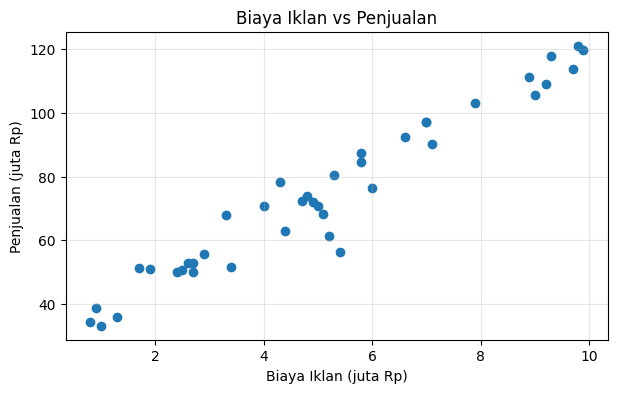

In [3]:
# Jawaban A1
ads = pd.read_csv('Ads_Data.csv')
display(ads.head())
print('Jumlah baris data:', len(ads))

# X harus 2 dimensi (n, 1) -> pakai [[ ]] agar tetap berbentuk DataFrame/2D
X = ads[['BiayaIklan']].to_numpy()
y = ads['Penjualan'].to_numpy()
print('Shape X:', X.shape, '| Shape y:', y.shape)

plt.figure(figsize=(7, 4))
plt.scatter(X[:, 0], y, color='tab:blue')
plt.title('Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(True, alpha=0.3)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [4]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('y_train:', y_train.shape)
print('y_test :', y_test.shape)

X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [5]:
# Jawaban A3
class LinearRegression:
    """Linear Regression sederhana (1 fitur) dengan Normal Equation: theta = (X^T X)^-1 X^T y"""
    def fit(self, X, y):
        X = np.asarray(X).reshape(-1, 1)
        y = np.asarray(y).reshape(-1, 1)
        Xb = np.c_[np.ones(len(X)), X]                       # tambah kolom 1 untuk intercept
        theta = np.linalg.pinv(Xb.T @ Xb) @ Xb.T @ y         # normal equation
        self.intercept_ = float(theta[0, 0])
        self.coef_ = float(theta[1, 0])
        return self

    def predict(self, X):
        X = np.asarray(X).reshape(-1, 1)
        return self.intercept_ + self.coef_ * X[:, 0]

lin = LinearRegression().fit(X_train, y_train)
print('Intercept (b)  :', lin.intercept_)
print('Koefisien (m)  :', lin.coef_)
print(f'Persamaan regresi: y_hat = {lin.intercept_:.4f} + ({lin.coef_:.4f} x BiayaIklan)')

Intercept (b)  : 29.429596916977136
Koefisien (m)  : 8.945593123729516
Persamaan regresi: y_hat = 29.4296 + (8.9456 x BiayaIklan)


**Jawaban A3 (interpretasi):**

Persamaan regresi yang diperoleh adalah $\hat{y} = 29{,}4296 + 8{,}9456 \cdot \text{BiayaIklan}$. Nilai koefisien $m = 8{,}9456$ berarti **setiap kenaikan biaya iklan sebesar Rp1 juta, penjualan per bulan diperkirakan naik sekitar Rp8,95 juta**, dengan asumsi hubungan keduanya linear. Tanda positif menunjukkan bahwa biaya iklan dan penjualan bergerak searah, sesuai pola scatter plot di Soal A1 yang naik dari kiri bawah ke kanan atas. Intercept $b = 29{,}4296$ adalah perkiraan penjualan ketika biaya iklan 0 (penjualan "dasar" tanpa iklan); angka ini hanya tafsiran kasar karena data terkecil kita berada di biaya iklan 0,8 juta, bukan 0.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [6]:
# Jawaban A4
def mae(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true).ravel(), np.asarray(y_pred).ravel()
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true).ravel(), np.asarray(y_pred).ravel()
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true).ravel(), np.asarray(y_pred).ravel()
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

def regression_report(y_true, y_pred):
    return {'MAE': mae(y_true, y_pred), 'MSE': mse(y_true, y_pred),
            'RMSE': rmse(y_true, y_pred), 'R2': r2_score(y_true, y_pred)}

pred_train = lin.predict(X_train)
pred_test = lin.predict(X_test)

metrics_A4 = pd.DataFrame([
    {'Data': 'Training', **regression_report(y_train, pred_train)},
    {'Data': 'Testing',  **regression_report(y_test,  pred_test)},
]).set_index('Data')
display(metrics_A4)

,MAE,MSE,RMSE,R2
Data,,,,
Training,4.6829,40.5038,6.3643,0.9387
Testing,4.0044,19.8542,4.4558,0.9395


**Jawaban A4 (analisis):**

RMSE pada data testing sebesar **4,4558** (juta Rp), artinya rata-rata prediksi penjualan model meleset sekitar Rp4,46 juta dari penjualan sebenarnya. Angka ini cukup kecil dibandingkan rentang penjualan pada data yang sekitar 33 sampai 121 juta. Nilai $R^2$ pada data testing adalah **0,9395** (training **0,9387**), sehingga sekitar 94% variasi penjualan dapat dijelaskan oleh biaya iklan. Hal ini sejalan dengan korelasi antara kedua variabel yang tinggi (sekitar 0,97) pada scatter plot A1.

Menurut saya model ini **sudah baik** untuk data sederhana dengan satu fitur. Error di data testing (RMSE 4,46; MAE 4,00) tidak lebih buruk dari data training (RMSE 6,36; MAE 4,68), jadi tidak ada tanda *overfitting*. Perlu dicatat bahwa data testing hanya 8 baris, sehingga hasil testing yang sedikit lebih baik dari training kemungkinan dipengaruhi oleh pembagian data yang kebetulan "mudah", bukan berarti model lebih akurat pada data baru.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/tmp/ipykernel_156/2798730207.py:16: RuntimeWarning: overflow encountered in square
  self.loss_history.append(np.mean(error ** 2))          # MSE
/tmp/ipykernel_156/2798730207.py:17: RuntimeWarning: overflow encountered in matmul
  theta = theta - self.lr * (2 / len(y)) * (Xb.T @ error)  # update gradient descent
/tmp/ipykernel_156/2798730207.py:17: RuntimeWarning: invalid value encountered in subtract
  theta = theta - self.lr * (2 / len(y)) * (Xb.T @ error)  # update gradient descent


,Intercept,Koefisien,Loss akhir (MSE)
Learning rate,,,
0.001,25.9695,9.4565,43.0416
0.02,29.4296,8.9456,40.5038
0.1,NaN,NaN,NaN
Normal Eq.,29.4296,8.9456,40.5038


Eigenvalue terbesar Hessian = 74.7204 -> learning rate stabil harus < 0.0268


lr=0.1: loss menjadi inf/nan mulai iterasi ke-188 (overflow)


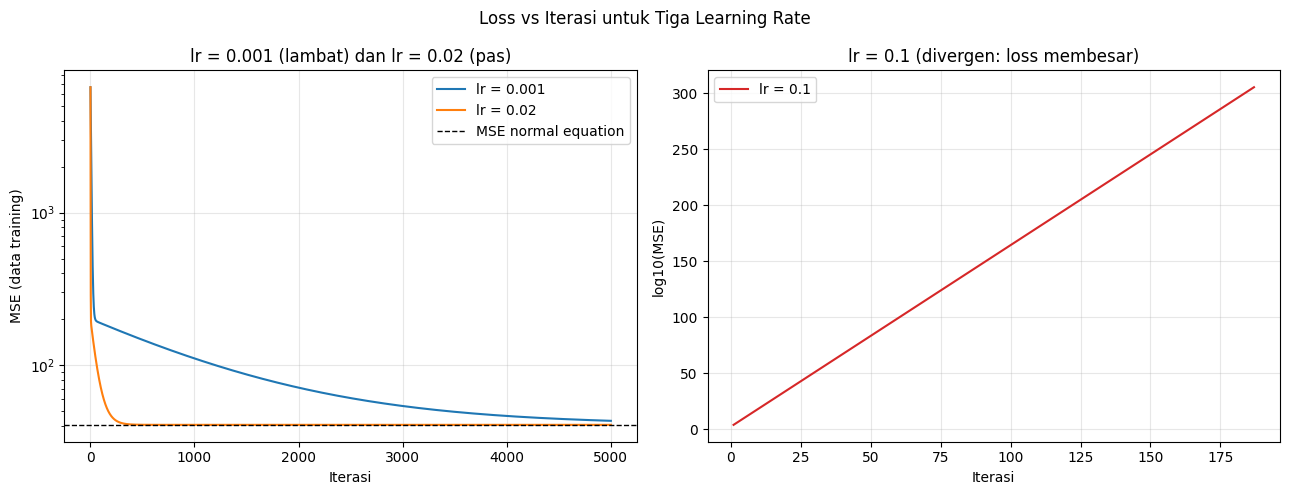

Loss lr=0.1 pada iterasi 1, 10, 50, 100: ['6.660e+03', '2.564e+18', '1.960e+83', '2.491e+164']


In [7]:
# Jawaban A5
class LinearRegressionGD:
    """Linear Regression (1 fitur) dengan Gradient Descent pada MSE (tanpa standardisasi, seperti materi)."""
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.lr = learning_rate
        self.n_iterations = n_iterations

    def fit(self, X, y):
        X = np.asarray(X).reshape(-1, 1)
        y = np.asarray(y).ravel()
        Xb = np.c_[np.ones(len(X)), X]
        theta = np.zeros(2)                      # [intercept, koefisien] mulai dari 0
        self.loss_history = []
        for _ in range(self.n_iterations):
            error = Xb @ theta - y
            self.loss_history.append(np.mean(error ** 2))          # MSE
            theta = theta - self.lr * (2 / len(y)) * (Xb.T @ error)  # update gradient descent
        self.intercept_, self.coef_ = theta
        return self

    def predict(self, X):
        return self.intercept_ + self.coef_ * np.asarray(X).reshape(-1)

learning_rates = [0.001, 0.02, 0.1]
gd_models = {}
rows = []
for lr in learning_rates:
    model = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)
    gd_models[lr] = model
    rows.append({'Learning rate': lr, 'Intercept': model.intercept_, 'Koefisien': model.coef_,
                 'Loss akhir (MSE)': model.loss_history[-1]})
rows.append({'Learning rate': 'Normal Eq.', 'Intercept': lin.intercept_, 'Koefisien': lin.coef_,
             'Loss akhir (MSE)': mse(y_train, lin.predict(X_train))})
display(pd.DataFrame(rows).set_index('Learning rate'))

# Batas learning rate yang stabil: lr < 2 / (eigenvalue terbesar Hessian)
Xb_tr = np.c_[np.ones(len(X_train)), X_train]
lam_max = np.linalg.eigvalsh((2 / len(y_train)) * Xb_tr.T @ Xb_tr).max()
print(f'Eigenvalue terbesar Hessian = {lam_max:.4f} -> learning rate stabil harus < {2/lam_max:.4f}')

# Grafik loss vs iterasi. Panel kiri: lr yang konvergen (skala log).
# Panel kanan: lr=0.1 yang divergen, digambar sebagai log10(loss) agar nilai raksasa tetap terbaca
# (iterasi dengan loss inf/nan akibat overflow tidak ikut digambar).
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for lr in [0.001, 0.02]:
    loss = np.asarray(gd_models[lr].loss_history, dtype=float)
    axes[0].plot(np.arange(1, len(loss) + 1), loss, label=f'lr = {lr}')
axes[0].axhline(mse(y_train, lin.predict(X_train)), color='k', ls='--', lw=1, label='MSE normal equation')
axes[0].set_yscale('log')
axes[0].set_xlabel('Iterasi'); axes[0].set_ylabel('MSE (data training)')
axes[0].set_title('lr = 0.001 (lambat) dan lr = 0.02 (pas)')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

loss = np.asarray(gd_models[0.1].loss_history, dtype=float)
ok = np.isfinite(loss)
axes[1].plot(np.arange(1, len(loss) + 1)[ok], np.log10(loss[ok]), color='tab:red', label='lr = 0.1')
axes[1].set_xlabel('Iterasi'); axes[1].set_ylabel('log10(MSE)')
axes[1].set_title('lr = 0.1 (divergen: loss membesar)')
axes[1].legend(); axes[1].grid(True, alpha=0.3)
if not ok.all():
    print(f'lr=0.1: loss menjadi inf/nan mulai iterasi ke-{np.argmax(~ok) + 1} (overflow)')
plt.suptitle('Loss vs Iterasi untuk Tiga Learning Rate')
plt.tight_layout()
plt.show()

print('Loss lr=0.1 pada iterasi 1, 10, 50, 100:', [f'{gd_models[0.1].loss_history[i-1]:.3e}' for i in (1, 10, 50, 100)])

**Jawaban A5 (analisis):**

Hasil normal equation (Soal A3) adalah intercept 29,4296 dan koefisien 8,9456 dengan MSE training 40,5038. Hasil gradient descent setelah 5000 iterasi (lihat tabel dan grafik di atas):

- **lr = 0,001 (terlalu lambat).** Setelah 5000 iterasi parameter masih belum sampai: intercept 25,9695 dan koefisien 9,4565, dengan loss akhir 43,0416 yang masih di atas MSE normal equation (40,5038). Pada panel kiri grafik, kurva loss turun sangat landai karena langkah update terlalu kecil, sehingga butuh iterasi jauh lebih banyak agar mencapai titik minimum.
- **lr = 0,02 (pas).** Parameter akhir 29,4296 dan 8,9456, sama persis dengan normal equation sampai 4 angka desimal, dan loss akhirnya 40,5038. Kurva loss turun cepat lalu mendatar di garis putus-putus (MSE normal equation), artinya sudah konvergen.
- **lr = 0,1 (divergen).** Pada panel kanan grafik (skala log10), loss justru membesar, bukan mengecil: sekitar 2,49 × 10^164 pada iterasi ke-100, lalu menjadi `inf`/`nan` sehingga intercept dan koefisien akhirnya `nan`. Langkah update terlalu besar sehingga parameter melompati titik minimum dan semakin jauh pada tiap iterasi (berosilasi dengan amplitudo yang terus membesar).

Penyebabnya: fitur `BiayaIklan` tidak distandardisasi (nilainya sampai 9,9), sehingga permukaan loss sangat curam pada arah tertentu. Eigenvalue terbesar Hessian MSE di data ini sekitar 74,72, sehingga gradient descent hanya stabil jika learning rate < 2/74,72 ≈ **0,0268**. Karena itu 0,02 stabil, sedangkan 0,1 melewati batas dan divergen. `RuntimeWarning: overflow` yang muncul berarti nilai parameter/loss sudah terlalu besar untuk ditampung tipe float64 (melebihi sekitar 1,8 × 10^308), jadi hasil perhitungannya berubah menjadi `inf`/`nan`. Ini adalah tanda bahwa training gagal konvergen, bukan bug program.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

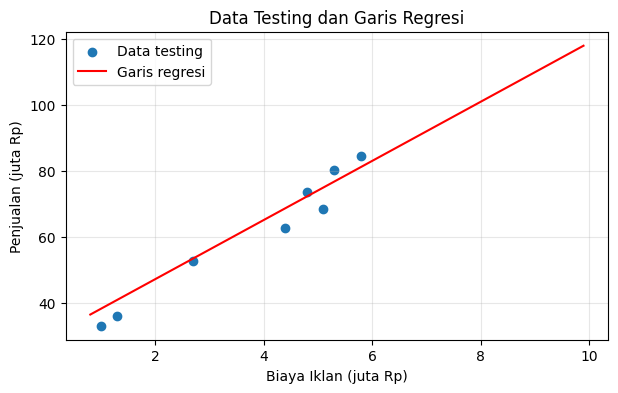

,BiayaIklan (juta Rp),Prediksi Penjualan (juta Rp),Dalam rentang data?
0,4.5,69.6848,True
1,7.0,92.0487,True
2,12.0,136.7767,False


Rentang BiayaIklan pada data: 0.8 - 9.9 | Rentang Penjualan: 33.2 - 121.1


In [8]:
# Jawaban A6
x_line = np.linspace(X[:, 0].min(), X[:, 0].max(), 100)

plt.figure(figsize=(7, 4))
plt.scatter(X_test[:, 0], y_test, color='tab:blue', label='Data testing')
plt.plot(x_line, lin.predict(x_line), color='red', label='Garis regresi')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.title('Data Testing dan Garis Regresi')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

biaya_baru = np.array([4.5, 7.0, 12.0])
prediksi = lin.predict(biaya_baru)
hasil_A6 = pd.DataFrame({'BiayaIklan (juta Rp)': biaya_baru,
                         'Prediksi Penjualan (juta Rp)': prediksi,
                         'Dalam rentang data?': (biaya_baru >= X.min()) & (biaya_baru <= X.max())})
display(hasil_A6)
print(f'Rentang BiayaIklan pada data: {X.min():.1f} - {X.max():.1f} | Rentang Penjualan: {y.min():.1f} - {y.max():.1f}')

**Jawaban A6 (analisis):**

Prediksi model: biaya iklan 4,5 juta menghasilkan penjualan sekitar **69,68 juta**, 7 juta sekitar **92,05 juta**, dan 12 juta sekitar **136,78 juta**. Dua prediksi pertama berada di dalam rentang data (biaya iklan 0,8 sampai 9,9 juta), jadi merupakan interpolasi dan cukup bisa dipercaya, dengan kesalahan wajar kira-kira sebesar RMSE (sekitar 4 sampai 6 juta).

Prediksi untuk 12 juta adalah **ekstrapolasi** karena melewati biaya iklan terbesar yang pernah diamati (9,9 juta), dan hasilnya (136,78 juta) juga lebih tinggi dari penjualan tertinggi di data (121,1 juta). Menurut saya prediksi ini **kurang dapat dipercaya**. Model hanya belajar dari pola pada rentang 0,8 sampai 9,9 juta, sedangkan di luar rentang itu hubungan belum tentu tetap linear; misalnya efek iklan bisa jenuh (*diminishing returns*) sehingga kenaikan penjualannya tidak sebesar 8,95 juta per 1 juta biaya iklan. Garis regresi juga tidak memberi ukuran ketidakpastian, jadi angka 136,78 sebaiknya hanya dianggap perkiraan kasar, bukan target yang pasti.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah email per kelas:
  Bukan Spam (0): 35
  Spam (1)      : 25
Shape Xc: (60, 2) | Shape yc: (60,)


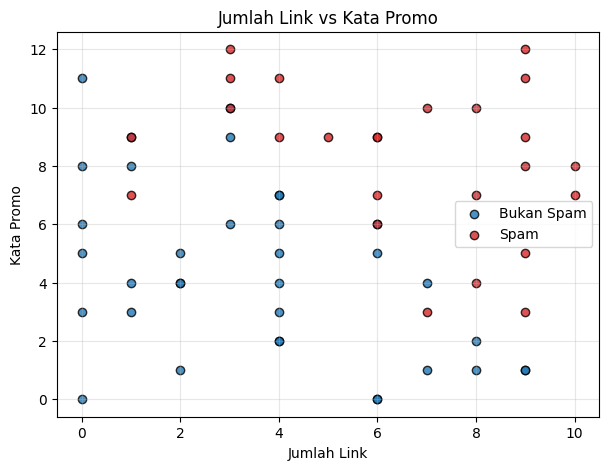

In [9]:
# Jawaban B1
email = pd.read_csv('Email_Data.csv')
display(email.head())

print('Jumlah email per kelas:')
jumlah_kelas = email['Spam'].value_counts().sort_index()
print(f'  Bukan Spam (0): {jumlah_kelas[0]}')
print(f'  Spam (1)      : {jumlah_kelas[1]}')

Xc = email[['JumlahLink', 'KataPromo']].to_numpy(dtype=float)
yc = email['Spam'].to_numpy(dtype=int)
print('Shape Xc:', Xc.shape, '| Shape yc:', yc.shape)

plt.figure(figsize=(7, 5))
for label, nama, warna in [(0, 'Bukan Spam', 'tab:blue'), (1, 'Spam', 'tab:red')]:
    mask = yc == label
    plt.scatter(Xc[mask, 0], Xc[mask, 1], label=nama, color=warna, alpha=0.8, edgecolors='k')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.title('Jumlah Link vs Kata Promo')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

X_train: (45, 2) | X_test: (15, 2)
y_train: (45,) | y_test: (15,)


Intercept (b)       : -8.730935697828881
Koefisien (m1, m2)  : [0.8172 0.7414]
P(Spam) = sigmoid(-8.7309 + (0.8172 x JumlahLink) + (0.7414 x KataPromo))


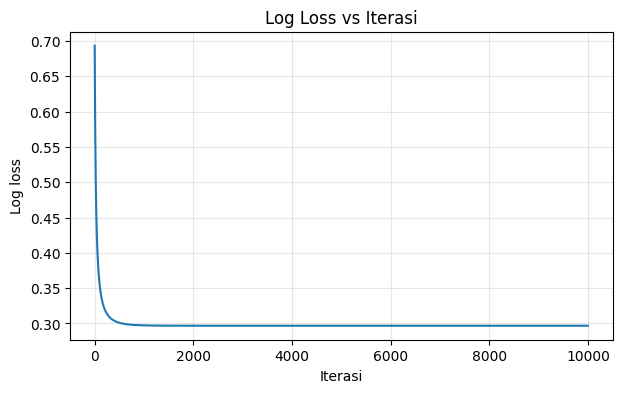

Log loss iterasi     1: 0.693147
Log loss iterasi   100: 0.355723
Log loss iterasi  1000: 0.297295
Log loss iterasi  5000: 0.296814
Log loss iterasi 10000: 0.296814


In [10]:
# Jawaban B2
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.25, random_state=RANDOM_STATE)
print('X_train:', Xc_train.shape, '| X_test:', Xc_test.shape)
print('y_train:', yc_train.shape, '| y_test:', yc_test.shape)

def sigmoid(z):
    z = np.clip(z, -500, 500)            # cegah overflow pada exp
    return 1 / (1 + np.exp(-z))

class LogisticRegression:
    """Logistic Regression dengan Gradient Descent pada log loss.
    Fitur distandardisasi saat training agar learning rate 0.1 stabil, lalu
    parameter dikembalikan ke skala asli sehingga predict_proba memakai data mentah."""
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.lr = learning_rate
        self.n_iterations = n_iterations

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()
        self.mean_ = X.mean(axis=0)
        self.std_ = X.std(axis=0)
        self.std_[self.std_ == 0] = 1
        Z = (X - self.mean_) / self.std_
        Zb = np.c_[np.ones(len(Z)), Z]
        theta = np.zeros(Zb.shape[1])
        self.loss_history = []
        eps = 1e-12
        for _ in range(self.n_iterations):
            p = sigmoid(Zb @ theta)
            self.loss_history.append(-np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps)))  # log loss
            grad = Zb.T @ (p - y) / len(y)
            theta = theta - self.lr * grad
        # kembalikan parameter ke skala fitur asli
        self.intercept_ = theta[0] - np.sum(theta[1:] * self.mean_ / self.std_)
        self.coef_ = theta[1:] / self.std_
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        return sigmoid(self.intercept_ + X @ self.coef_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

logit = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(Xc_train, yc_train)
print('Intercept (b)       :', logit.intercept_)
print('Koefisien (m1, m2)  :', logit.coef_)
print(f'P(Spam) = sigmoid({logit.intercept_:.4f} + ({logit.coef_[0]:.4f} x JumlahLink) + ({logit.coef_[1]:.4f} x KataPromo))')

plt.figure(figsize=(7, 4))
plt.plot(logit.loss_history)
plt.xlabel('Iterasi')
plt.ylabel('Log loss')
plt.title('Log Loss vs Iterasi')
plt.grid(True, alpha=0.3)
plt.show()
for it in (1, 100, 1000, 5000, 10000):
    print(f'Log loss iterasi {it:>5}: {logit.loss_history[it-1]:.6f}')

**Jawaban B2 (analisis):**

Persamaan yang diperoleh: $P(\text{Spam}) = \sigma(-8{,}7309 + 0{,}8172 \cdot \text{JumlahLink} + 0{,}7414 \cdot \text{KataPromo})$. Kedua koefisien bernilai positif, artinya makin banyak link dan makin banyak kata promosi, makin besar peluang email dianggap spam. Setiap tambahan 1 link menaikkan *odds* spam sekitar $e^{0{,}8172} \approx 2{,}26$ kali, dan setiap tambahan 1 kata promosi menaikkan *odds* sekitar $e^{0{,}7414} \approx 2{,}10$ kali (dengan fitur lain tetap).

Pada grafik log loss, loss mulai dari **0,6931** (sama dengan $\ln 2$, karena awalnya semua parameter 0 sehingga prediksi 0,5 untuk semua data) dan turun cepat menjadi 0,3557 pada iterasi ke-100, 0,2973 pada iterasi ke-1000, dan akhirnya **0,2968** pada iterasi ke-10000. Setelah sekitar iterasi 1000 kurvanya sudah mendatar (perubahan antara iterasi 5000 dan 10000 hampir nol), jadi loss **sudah turun dan stabil**, artinya model sudah konvergen. Loss akhir tidak mendekati 0 karena kedua kelas pada data saling tumpang tindih sehingga tidak bisa dipisahkan sempurna oleh satu garis.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [11]:
# Jawaban B3
def accuracy_score(y_true, y_pred):
    return np.mean(np.asarray(y_true) == np.asarray(y_pred))

def confusion_matrix(y_true, y_pred):
    """Baris = kelas aktual (0, 1), kolom = kelas prediksi (0, 1): [[TN, FP], [FN, TP]]"""
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])

def precision_score(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion_matrix(y_true, y_pred)
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_score(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion_matrix(y_true, y_pred)
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(y_true, y_pred):
    p, r = precision_score(y_true, y_pred), recall_score(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0.0

prob_test = logit.predict_proba(Xc_test)
pred_test_c = (prob_test >= 0.5).astype(int)

cm = confusion_matrix(yc_test, pred_test_c)
print('Confusion matrix (baris = aktual 0,1 ; kolom = prediksi 0,1):')
print(cm)
print(pd.DataFrame(cm, index=['Aktual Bukan Spam', 'Aktual Spam'], columns=['Prediksi Bukan Spam', 'Prediksi Spam']))

(tn, fp), (fn, tp) = cm
metrics_B3 = pd.DataFrame([{
    'Accuracy': accuracy_score(yc_test, pred_test_c),
    'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
    'Precision': precision_score(yc_test, pred_test_c),
    'Recall': recall_score(yc_test, pred_test_c),
    'F1': f1_score(yc_test, pred_test_c)}])
display(metrics_B3)

Confusion matrix (baris = aktual 0,1 ; kolom = prediksi 0,1):
[[9 1]
 [0 5]]
                   Prediksi Bukan Spam  Prediksi Spam
Aktual Bukan Spam                    9              1
Aktual Spam                          0              5


,Accuracy,TN,FP,FN,TP,Precision,Recall,F1
0,0.9333,9,1,0,5,0.8333,1.0,0.9091


**Jawaban B3 (analisis):**

Pada data testing (15 email: 10 bukan spam dan 5 spam) diperoleh confusion matrix `[[9, 1], [0, 5]]`, yaitu TN = 9, FP = 1, FN = 0, TP = 5, dengan accuracy **0,9333**, precision **0,8333**, recall **1,0000**, dan F1 **0,9091**.

- **FP (false positive)** adalah email yang sebenarnya *bukan spam* tetapi diprediksi *spam*, sehingga masuk ke folder spam. Pada hasil kita ada 1 kasus.
- **FN (false negative)** adalah email yang sebenarnya *spam* tetapi lolos diprediksi *bukan spam*, sehingga masuk ke kotak masuk. Pada hasil kita FN = 0, jadi semua spam berhasil terdeteksi (recall 1,0).

Menurut saya **FP lebih merugikan pengguna**. Email sah yang salah masuk folder spam, misalnya tagihan, undangan wawancara, atau informasi kuliah, bisa terlewat dan menimbulkan kerugian nyata. Sebaliknya FN hanya membuat pengguna melihat satu email spam di kotak masuk yang bisa langsung dihapus, sehingga dampaknya lebih kecil. Karena itu, filter spam sebaiknya menjaga precision tetap tinggi, dan kita lihat pengaruhnya pada eksperimen threshold di Soal B5.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: KataPromo = -(-8.7309 + (0.8172 x JumlahLink)) / (0.7414)
                 = 11.7770 + (-1.1022 x JumlahLink)


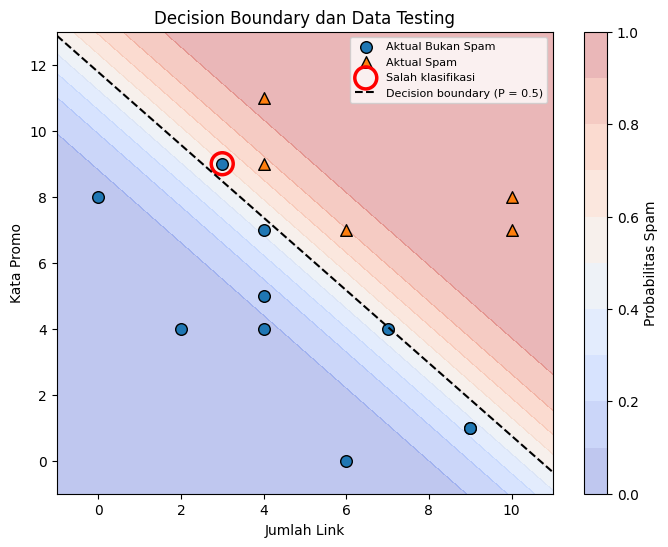

Indeks data testing yang salah klasifikasi (mulai dari 0): [7]


,Indeks,JumlahLink,KataPromo,Aktual,Prediksi,P(Spam)
0,7,3.0,9.0,0,1,0.5969


In [12]:
# Jawaban B4
b = logit.intercept_
m1, m2 = logit.coef_
print(f'Decision boundary: KataPromo = -({b:.4f} + ({m1:.4f} x JumlahLink)) / ({m2:.4f})')
print(f'                 = {-b/m2:.4f} + ({-m1/m2:.4f} x JumlahLink)')

# Grid untuk background probabilitas
xx, yy = np.meshgrid(np.linspace(Xc[:, 0].min() - 1, Xc[:, 0].max() + 1, 200),
                     np.linspace(Xc[:, 1].min() - 1, Xc[:, 1].max() + 1, 200))
zz = logit.predict_proba(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

salah = pred_test_c != yc_test      # data testing yang salah diklasifikasikan

plt.figure(figsize=(8, 6))
cs = plt.contourf(xx, yy, zz, levels=np.linspace(0, 1, 11), alpha=0.35, cmap='coolwarm')
plt.colorbar(cs, label='Probabilitas Spam')
for label, nama, marker in [(0, 'Bukan Spam', 'o'), (1, 'Spam', '^')]:
    mask = yc_test == label
    plt.scatter(Xc_test[mask, 0], Xc_test[mask, 1], marker=marker, edgecolors='black', s=70,
                label=f'Aktual {nama}')
if salah.any():
    plt.scatter(Xc_test[salah, 0], Xc_test[salah, 1], s=250, facecolors='none',
                edgecolors='red', linewidths=2.5, label='Salah klasifikasi')
x_vals = np.linspace(Xc[:, 0].min() - 1, Xc[:, 0].max() + 1, 200)
plt.plot(x_vals, -(b + m1 * x_vals) / m2, 'k--', label='Decision boundary (P = 0.5)')
plt.xlim(xx.min(), xx.max()); plt.ylim(yy.min(), yy.max())
plt.xlabel('Jumlah Link'); plt.ylabel('Kata Promo')
plt.title('Decision Boundary dan Data Testing')
plt.legend(loc='upper right', fontsize=8)
plt.show()

print('Indeks data testing yang salah klasifikasi (mulai dari 0):', np.where(salah)[0].tolist())
salah_df = pd.DataFrame({'Indeks': np.where(salah)[0],
                         'JumlahLink': Xc_test[salah, 0], 'KataPromo': Xc_test[salah, 1],
                         'Aktual': yc_test[salah], 'Prediksi': pred_test_c[salah],
                         'P(Spam)': prob_test[salah]})
display(salah_df)

**Jawaban B4 (analisis):**

Decision boundary yang diperoleh adalah $x_2 = -\dfrac{-8{,}7309 + 0{,}8172\,x_1}{0{,}7414} \approx 11{,}7770 - 1{,}1022\,x_1$, yaitu garis lurus dengan kemiringan negatif. Titik di atas garis (kombinasi link dan kata promosi yang banyak) diprediksi **spam**, titik di bawahnya diprediksi **bukan spam**. Pada grafik, daerah merah (probabilitas spam tinggi) berada di kanan atas dan daerah biru di kiri bawah.

Dari 15 data testing hanya **1 data yang salah diklasifikasikan**, yaitu indeks ke-7 (mulai dari 0) dengan `JumlahLink = 3` dan `KataPromo = 9`. Email ini sebenarnya *bukan spam* tetapi model memberi probabilitas spam 0,597 sehingga diprediksi spam (kasus FP yang sama dengan Soal B3). Titiknya berada sangat dekat dengan garis boundary (ditandai lingkaran merah), jadi kesalahan ini wajar karena kasus tersebut berada di daerah abu-abu antara kedua kelas.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [13]:
# Jawaban B5
prob_test = logit.predict_proba(Xc_test)       # probabilitas spam untuk data testing

rows = []
for threshold in [0.3, 0.5, 0.7]:
    pred_t = (prob_test >= threshold).astype(int)
    (tn, fp), (fn, tp) = confusion_matrix(yc_test, pred_t)
    rows.append({'Threshold': threshold, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
                 'Precision': precision_score(yc_test, pred_t),
                 'Recall': recall_score(yc_test, pred_t),
                 'Accuracy': accuracy_score(yc_test, pred_t)})
tabel_threshold = pd.DataFrame(rows).set_index('Threshold')
display(tabel_threshold)

,TN,FP,FN,TP,Precision,Recall,Accuracy
Threshold,,,,,,,
0.3,5,5,0,5,0.5000,1.0,0.6667
0.5,9,1,0,5,0.8333,1.0,0.9333
0.7,10,0,0,5,1.0000,1.0,1.0000


**Jawaban B5 (analisis):**

| Threshold | TN | FP | FN | TP | Precision | Recall | Accuracy |
|---|---|---|---|---|---|---|---|
| 0,3 | 5 | 5 | 0 | 5 | 0,5000 | 1,0 | 0,6667 |
| 0,5 | 9 | 1 | 0 | 5 | 0,8333 | 1,0 | 0,9333 |
| 0,7 | 10 | 0 | 0 | 5 | 1,0000 | 1,0 | 1,0000 |

**Menurunkan threshold** (0,3) membuat model lebih "mudah curiga": lebih banyak email diprediksi spam sehingga FP naik dari 1 menjadi 5 dan precision turun menjadi 0,50, sementara recall tetap 1,0 karena semua spam memang sudah tertangkap. **Menaikkan threshold** (0,7) membuat model lebih selektif: FP turun menjadi 0 dan precision naik menjadi 1,0. Secara umum, threshold tinggi cenderung menaikkan precision tetapi berisiko menurunkan recall (spam yang probabilitasnya sedang bisa lolos), sedangkan threshold rendah sebaliknya. Pada data testing ini recall tetap 1,0 di ketiga threshold, jadi menaikkan threshold sampai 0,7 tidak merugikan.

Berdasarkan Soal B3 (FP lebih merugikan daripada FN), saya memilih **threshold 0,7**. Alasannya, threshold ini menghasilkan FP = 0 dan precision 1,0, sehingga tidak ada email penting yang salah masuk folder spam, sementara recall tetap 1,0. Meski begitu, data testing hanya 15 baris, jadi pada data baru threshold setinggi ini mungkin meloloskan sebagian spam; trade-off tersebut masih dapat diterima untuk kasus ini.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [14]:
# Jawaban B6
THRESHOLD_PILIHAN = 0.7     # threshold pilihan dari Soal B5

email_baru = pd.DataFrame({'Email': ['E1', 'E2', 'E3', 'E4'],
                           'JumlahLink': [1, 5, 9, 2],
                           'KataPromo': [2, 6, 10, 11]})
X_baru = email_baru[['JumlahLink', 'KataPromo']].to_numpy(dtype=float)

email_baru['Probabilitas Spam'] = logit.predict_proba(X_baru)
email_baru['Prediksi'] = np.where(email_baru['Probabilitas Spam'] >= THRESHOLD_PILIHAN, 'Spam', 'Bukan Spam')
email_baru['Threshold'] = THRESHOLD_PILIHAN
display(email_baru)

for _, r in email_baru.iterrows():
    print(f"{r['Email']}: P(Spam) = {r['Probabilitas Spam']:.4f} -> {r['Prediksi']}")

,Email,JumlahLink,KataPromo,Probabilitas Spam,Prediksi,Threshold
0,E1,1,2,0.0016,Bukan Spam,0.7
1,E2,5,6,0.4509,Bukan Spam,0.7
2,E3,9,10,0.9976,Spam,0.7
3,E4,2,11,0.7424,Spam,0.7


E1: P(Spam) = 0.0016 -> Bukan Spam
E2: P(Spam) = 0.4509 -> Bukan Spam
E3: P(Spam) = 0.9976 -> Spam
E4: P(Spam) = 0.7424 -> Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**
Logistic Regression termasuk klasifikasi karena tujuan akhirnya adalah memprediksi **kelas** (misalnya spam atau bukan spam), bukan angka kontinu. Kata "regression" ada pada namanya karena di dalamnya model tetap menghitung kombinasi linear fitur, $z = b + m_1x_1 + m_2x_2$, seperti pada regresi linear. Fungsi **sigmoid** $\sigma(z) = \frac{1}{1+e^{-z}}$ kemudian mengubah nilai $z$ yang bisa bernilai berapa pun menjadi probabilitas antara 0 dan 1. Probabilitas itu dibandingkan dengan threshold (misalnya 0,5) untuk menentukan kelas akhir; pada data email kita, contohnya $P(\text{Spam})$ = 0,9976 untuk E3 sehingga diklasifikasikan sebagai spam.

**Jawaban C2:**
**Normal equation** menghitung parameter langsung dalam satu kali perhitungan dengan rumus matriks $\theta = (X^TX)^{-1}X^Ty$, sehingga hasilnya eksak dan tidak perlu menentukan learning rate. **Gradient descent** mencari parameter secara bertahap: dimulai dari nilai awal, lalu diperbarui sedikit demi sedikit searah gradien negatif loss sampai konvergen, dan hasilnya bergantung pada learning rate serta jumlah iterasi (seperti terlihat di Soal A5). Gradient descent sebaiknya dipakai ketika jumlah data atau jumlah fitur sangat besar, karena normal equation harus membalik matriks $X^TX$ yang mahal (kira-kira berbanding kubik dengan jumlah fitur). Gradient descent juga bisa dipakai untuk model yang tidak punya solusi tertutup, seperti Logistic Regression.

**Jawaban C3:**
Model harus dievaluasi pada **data testing** karena data tersebut tidak dipakai saat training, sehingga hasilnya menggambarkan kemampuan model pada data baru (generalisasi). Jika dievaluasi pada data training saja, skor bisa terlihat bagus padahal model hanya menghafal data yang sudah dilihat. **Overfitting** terjadi ketika model terlalu menyesuaikan diri dengan data training, termasuk noise-nya, sehingga performanya sangat baik pada data training tetapi jauh lebih buruk pada data testing atau data baru. Tanda yang biasa terlihat adalah selisih besar antara skor training dan testing; pada Soal A4 selisihnya kecil (R² 0,9387 vs 0,9395) sehingga tidak ada indikasi overfitting.

**Jawaban C4:**
Linear Regression menghasilkan output **nilai kontinu** (misalnya penjualan dalam juta rupiah), sehingga kesalahan paling wajar diukur dari selisih nilai prediksi dan nilai sebenarnya; MSE merata-ratakan kuadrat selisih itu dan memberi penalti lebih besar pada kesalahan besar. Logistic Regression menghasilkan **probabilitas kelas** antara 0 dan 1, sehingga yang dinilai adalah seberapa baik probabilitas tersebut cocok dengan label 0 atau 1, dan itu diukur oleh **log loss**: $-[y\log p + (1-y)\log(1-p)]$. Log loss memberi penalti sangat besar pada prediksi yang yakin tetapi salah (misalnya $p$ = 0,99 padahal labelnya 0), dan secara matematis berasal dari prinsip *maximum likelihood* untuk data biner. Selain itu, jika MSE dipakai bersama sigmoid, permukaan loss menjadi tidak cembung sehingga gradient descent lebih sulit menemukan minimum, sedangkan log loss tetap cembung.

**Jawaban C5:**
Hasil angka bisa berbeda terutama karena `random_state` yang berbeda (2 digit terakhir NIM masing-masing), sehingga pembagian data training dan testing berbeda dan model dilatih serta diuji pada baris data yang berbeda. Karena data testing kecil (8 baris pada Bagian A dan 15 baris pada Bagian B), perbedaan pembagian saja bisa mengubah akurasi, RMSE, atau $R^2$ cukup jelas. Selain itu, hasil juga dipengaruhi detail implementasi seperti ada atau tidaknya standardisasi fitur, nilai awal parameter, learning rate, dan jumlah iterasi pada gradient descent. Pada `random_state` yang sama pun hasil bisa sedikit berbeda jika caranya mengacak/membagi data tidak persis sama.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [15]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.linear_model import LogisticRegression as SkLogisticRegression

# --- Linear Regression: NumPy vs scikit-learn (data training yang sama) ---
sk_lin = SkLinearRegression().fit(X_train, y_train)
sk_lin_pred = sk_lin.predict(X_test)
tabel_lin = pd.DataFrame([
    {'Model': 'NumPy (normal equation)', 'Intercept': lin.intercept_, 'Koefisien': lin.coef_,
     'RMSE test': rmse(y_test, lin.predict(X_test)), 'R2 test': r2_score(y_test, lin.predict(X_test))},
    {'Model': 'scikit-learn', 'Intercept': sk_lin.intercept_, 'Koefisien': sk_lin.coef_[0],
     'RMSE test': rmse(y_test, sk_lin_pred), 'R2 test': r2_score(y_test, sk_lin_pred)},
]).set_index('Model')
display(tabel_lin)
print('Selisih koefisien (NumPy - sklearn):', lin.coef_ - sk_lin.coef_[0])

# --- Logistic Regression: NumPy vs sklearn default (L2, C=1) vs sklearn hampir tanpa regularisasi (C besar) ---
sk_log = SkLogisticRegression(max_iter=10000, random_state=RANDOM_STATE).fit(Xc_train, yc_train)          # default: L2, C=1.0
sk_log_noreg = SkLogisticRegression(C=1e10, max_iter=100000, random_state=RANDOM_STATE).fit(Xc_train, yc_train)  # regularisasi sangat lemah

baris = []
for nama, intercept, coef, pred in [
        ('NumPy (tanpa regularisasi)', logit.intercept_, logit.coef_, logit.predict(Xc_test)),
        ('sklearn default (L2, C=1)', sk_log.intercept_[0], sk_log.coef_[0], sk_log.predict(Xc_test)),
        ('sklearn (C=1e10, ~tanpa regularisasi)', sk_log_noreg.intercept_[0], sk_log_noreg.coef_[0], sk_log_noreg.predict(Xc_test))]:
    baris.append({'Model': nama, 'Intercept': intercept, 'm1 (JumlahLink)': coef[0], 'm2 (KataPromo)': coef[1],
                  'Accuracy': accuracy_score(yc_test, pred), 'Precision': precision_score(yc_test, pred),
                  'Recall': recall_score(yc_test, pred), 'F1': f1_score(yc_test, pred)})
display(pd.DataFrame(baris).set_index('Model'))

,Intercept,Koefisien,RMSE test,R2 test
Model,,,,
NumPy (normal equation),29.4296,8.9456,4.4558,0.9395
scikit-learn,29.4296,8.9456,4.4558,0.9395


Selisih koefisien (NumPy - sklearn): 3.375077994860476e-14


,Intercept,m1 (JumlahLink),m2 (KataPromo),Accuracy,Precision,Recall,F1
Model,,,,,,,
NumPy (tanpa regularisasi),-8.7309,0.8172,0.7414,0.9333,0.8333,1.0,0.9091
"sklearn default (L2, C=1)",-7.9227,0.7384,0.6735,0.9333,0.8333,1.0,0.9091
"sklearn (C=1e10, ~tanpa regularisasi)",-8.7314,0.8172,0.7414,0.9333,0.8333,1.0,0.9091


**Jawaban Bonus (analisis):**

**Linear Regression.** Intercept dan koefisien hasil implementasi NumPy sama dengan scikit-learn sampai belasan angka desimal (selisih koefisien sekitar 10^-14), dan $R^2$ testing sama yaitu 0,9395. Hal ini wajar karena keduanya menyelesaikan masalah kuadrat terkecil yang sama dan memiliki solusi eksak yang unik.

**Logistic Regression.** Dengan pengaturan default, scikit-learn menghasilkan koefisien yang berbeda dari implementasi NumPy saya: intercept sekitar -7,9227 dengan koefisien (0,7384; 0,6735), dibandingkan -8,7309 dengan (0,8172; 0,7414) pada NumPy. Penyebab utamanya adalah scikit-learn secara default memakai **regularisasi L2** (`penalty='l2'`, `C=1.0`) yang menghukum koefisien besar sehingga koefisien "ditarik" mendekati 0, sedangkan implementasi NumPy saya hanya meminimalkan log loss tanpa regularisasi. Perbedaan lainnya adalah solver: scikit-learn memakai optimisasi lain (default `lbfgs`) dan bukan gradient descent biasa. Saat regularisasi dibuat sangat lemah (`C=1e10`, hasilnya pada tabel di atas), koefisien scikit-learn menjadi sangat dekat dengan hasil NumPy, yang menunjukkan bahwa implementasi saya benar dan selisih tadi memang berasal dari regularisasi. Walaupun koefisiennya berbeda, metrik pada data testing sama (accuracy 0,9333, precision 0,8333, recall 1,0, F1 0,9091) karena posisi garis decision boundary hanya bergeser sedikit dan tidak mengubah klasifikasi 15 data testing ini.